# Data Quality & Profiling — Dataset EDA

Profiles the sales dataset: what columns exist, how clean they are, what values they hold, and which KPIs the data can support. Dataset: UCI Online Retail II — a UK online retailer, ~2 years.

Sections: (1) overview, (2) column profile, (3) data quality, (4) business dimensions, (5) temporal patterns & seasonality, (6) orders, returns & concentration, (7) numeric distributions, (8) field availability -> KPIs, (9) takeaways.

To run: place `online_retail_II.xlsx` next to this notebook (or set the `RETAIL_XLSX` environment variable to its path), then Run All. Requires pandas, numpy, matplotlib, openpyxl, and holidays.

In [183]:
%matplotlib inline
import os, warnings

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = os.environ.get("RETAIL_XLSX", "online_retail_II.xlsx")
xl = pd.ExcelFile(DATA_PATH)
raw = pd.concat([pd.read_excel(xl, sheet_name=s) for s in xl.sheet_names], ignore_index=True)
print("Rows:", f"{len(raw):,}", "| Columns:", list(raw.columns))
raw.head()

Rows: 1,067,371 | Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 1. Dataset overview

In [184]:
print("Shape:", raw.shape)
print("Date range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())
print("Memory:", f"{raw.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
print("\nDtypes:")
print(raw.dtypes)

Shape: (1067371, 8)
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Memory: 261.2 MB

Dtypes:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


## 2. Column profile

One row per column: type, how much is missing, how many distinct values, and a range or sample.

In [185]:
prof = []
for c in raw.columns:
    col = raw[c]
    row = {
        "column": c,
        "dtype": str(col.dtype),
        "missing_%": round(col.isna().mean() * 100, 1),
        "unique": int(col.nunique(dropna=True)),
    }
    if pd.api.types.is_numeric_dtype(col):
        row["min"], row["max"] = round(float(col.min()), 2), round(float(col.max()), 2)
        row["mean"] = round(float(col.mean()), 2)
    else:
        row["sample"] = ", ".join(col.dropna().astype(str).value_counts().head(2).index)
    prof.append(row)
pd.DataFrame(prof)

,column,dtype,missing_%,unique,sample,min,max,mean
0,Invoice,object,0.0,53628,"537434, 538071",NaN,NaN,NaN
1,StockCode,object,0.0,5305,"85123A, 22423",NaN,NaN,NaN
2,Description,object,0.4,5698,"WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CA...",NaN,NaN,NaN
3,Quantity,int64,0.0,1057,NaN,-80995.00,80995.0,9.94
4,InvoiceDate,datetime64[ns],0.0,47635,"2010-12-06 16:57:00, 2010-12-09 14:09:00",NaN,NaN,NaN
5,Price,float64,0.0,2807,NaN,-53594.36,38970.0,4.65
6,Customer ID,float64,22.8,5942,NaN,12346.00,18287.0,15324.64
7,Country,object,0.0,43,"United Kingdom, EIRE",NaN,NaN,NaN


## 3. Data quality

Duplicates, missing values, and invalid records — the issues the cleaning pipeline (duplicate removal, missing-value handling) has to deal with.

Exact duplicate rows: 34,335 (3.2%)


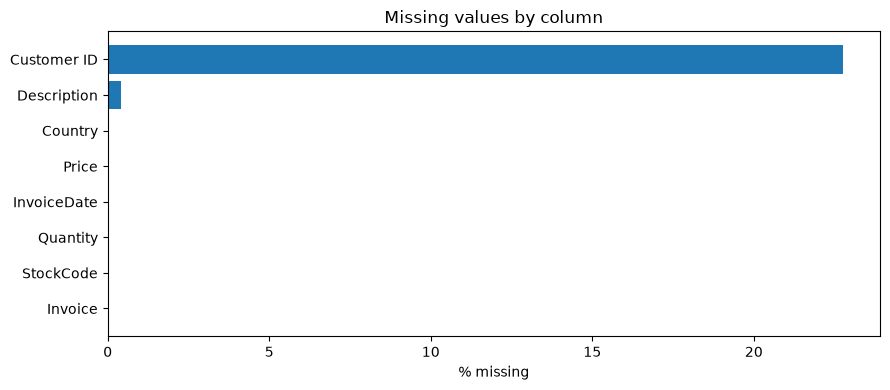

Missing in critical fields:
InvoiceDate    0
StockCode      0
Quantity       0
Price          0
dtype: int64


In [186]:
print("Exact duplicate rows:", f"{int(raw.duplicated().sum()):,}", f"({raw.duplicated().mean() * 100:.1f}%)")

# Missing values per column
miss = (raw.isna().mean() * 100).sort_values()
plt.figure(figsize=(9, 4))
plt.barh(miss.index, miss.values)
plt.xlabel("% missing")
plt.title("Missing values by column")
plt.tight_layout()
plt.show()

# Critical fields for any revenue analysis
critical = ["InvoiceDate", "StockCode", "Quantity", "Price"]
print("Missing in critical fields:")
print(raw[critical].isna().sum())

In [187]:
# Example of exact duplicate rows (every column identical) — what duplicate removal collapses.
raw[raw.duplicated(keep=False)].sort_values(list(raw.columns)).head(4)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [188]:
# Invalid / non-standard records
inv = raw["Invoice"].astype(str)
code_ = raw["StockCode"].astype(str).str.upper()
summary = pd.Series(
    {
        "cancellations (invoice C...)": int(inv.str.startswith("C").sum()),
        "negative quantity (returns)": int((raw["Quantity"] < 0).sum()),
        "zero / negative price": int((raw["Price"] <= 0).sum()),
        "non-product stock codes": int((~code_.str.match(r"^\d{5}")).sum()),
        "missing Customer ID": int(raw["Customer ID"].isna().sum()),
    }
)
print("Records needing attention:")
print(summary.to_string())

Records needing attention:
cancellations (invoice C...)     19494
negative quantity (returns)      22950
zero / negative price             6207
non-product stock codes           6093
missing Customer ID             243007


### What the non-product codes are

The non-5-digit stock codes flagged above, by revenue impact. Postage, fees, and adjustments dominate; the small `DCGS...` entries are actual products with non-standard codes.

In [189]:
code_ = raw["StockCode"].astype(str).str.upper()
nonprod = ~code_.str.match(r"^\d{5}")
rev = raw["Quantity"] * raw["Price"]
tbl = (
    pd.DataFrame({"code": code_[nonprod], "desc": raw.loc[nonprod, "Description"], "rev": rev[nonprod]})
    .groupby("code")
    .agg(
        rows=("rev", "size"),
        net_revenue=("rev", "sum"),
        example=("desc", lambda s: s.dropna().astype(str).iloc[0] if s.notna().any() else ""),
    )
)
tbl = tbl.reindex(tbl["net_revenue"].abs().sort_values(ascending=False).index)
from IPython.display import display

print("Distinct non-product codes:", len(tbl))
with pd.option_context("display.max_rows", None):
    display(tbl.assign(net_revenue=tbl["net_revenue"].round(0)))

Distinct non-product codes: 61


,rows,net_revenue,example
code,,,
DOT,1446,322647.0,DOTCOM POSTAGE
AMAZONFEE,43,-260764.0,AMAZON FEE
B,6,-147614.0,Adjust bad debt
POST,2122,112341.0,POSTAGE
M,1426,-82781.0,Manual
BANK CHARGES,102,-35563.0,Bank Charges
D,177,-13485.0,Discount
C2,282,13386.0,CARRIAGE
CRUK,16,-7933.0,CRUK Commission


## 4. Business dimensions

Unique products : 5305
Unique customers: 5942
Countries       : 43


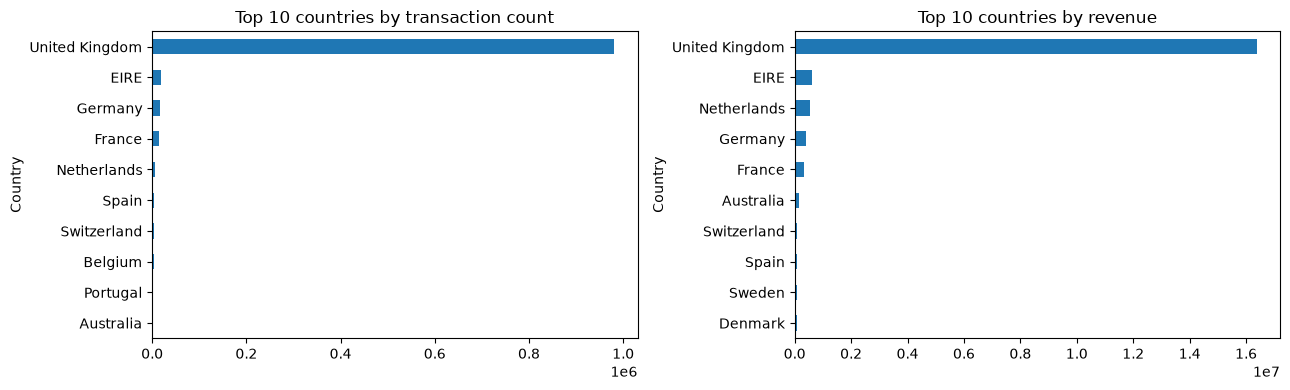

In [190]:
print("Unique products :", raw["StockCode"].nunique())
print("Unique customers:", raw["Customer ID"].nunique())
print("Countries       :", raw["Country"].nunique())

raw["revenue"] = raw["Quantity"] * raw["Price"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
raw["Country"].value_counts().head(10)[::-1].plot(kind="barh", ax=ax[0])
ax[0].set_title("Top 10 countries by transaction count")
raw.groupby("Country")["revenue"].sum().sort_values().tail(10).plot(kind="barh", ax=ax[1])
ax[1].set_title("Top 10 countries by revenue")
plt.tight_layout()
plt.show()

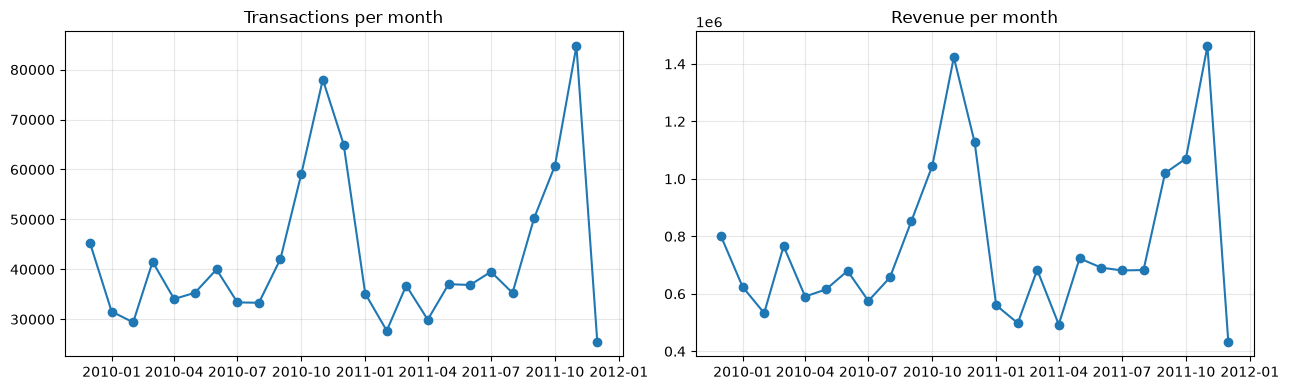

In [191]:
# Activity over time
ts = raw.dropna(subset=["InvoiceDate"]).set_index("InvoiceDate")
monthly = ts.resample("MS").agg(transactions=("Invoice", "count"), revenue=("revenue", "sum"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(monthly.index, monthly["transactions"], "-o")
ax[0].set_title("Transactions per month")
ax[1].plot(monthly.index, monthly["revenue"], "-o")
ax[1].set_title("Revenue per month")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Temporal patterns & seasonality

The structure a revenue forecast relies on: the overall trend, the weekly cycle, the yearly cycle, and the holiday effect. Built from a daily revenue series (revenue summed per calendar day; days with no sales counted as 0). Every UK public holiday in this data is a non-trading day, so holiday revenue is 0 — here the holiday effect is a store-closure effect.

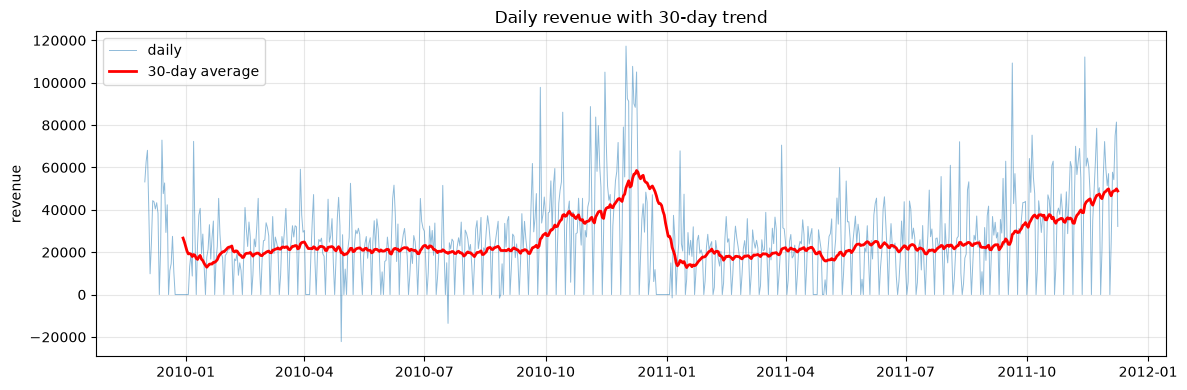

In [192]:
# Daily revenue series: revenue per calendar day, closed days filled with 0.
rev_line = raw["Quantity"] * raw["Price"]
day = raw["InvoiceDate"].dt.normalize()
daily_rev = rev_line.groupby(day).sum().sort_index()
daily_rev = daily_rev.reindex(pd.date_range(daily_rev.index.min(), daily_rev.index.max(), freq="D"), fill_value=0.0)
monthly_rev = daily_rev.resample("MS").sum()

plt.figure(figsize=(12, 4))
plt.plot(daily_rev.index, daily_rev.values, lw=0.7, alpha=0.5, label="daily")
plt.plot(daily_rev.index, daily_rev.rolling(30).mean(), "r", lw=2, label="30-day average")
plt.title("Daily revenue with 30-day trend")
plt.ylabel("revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

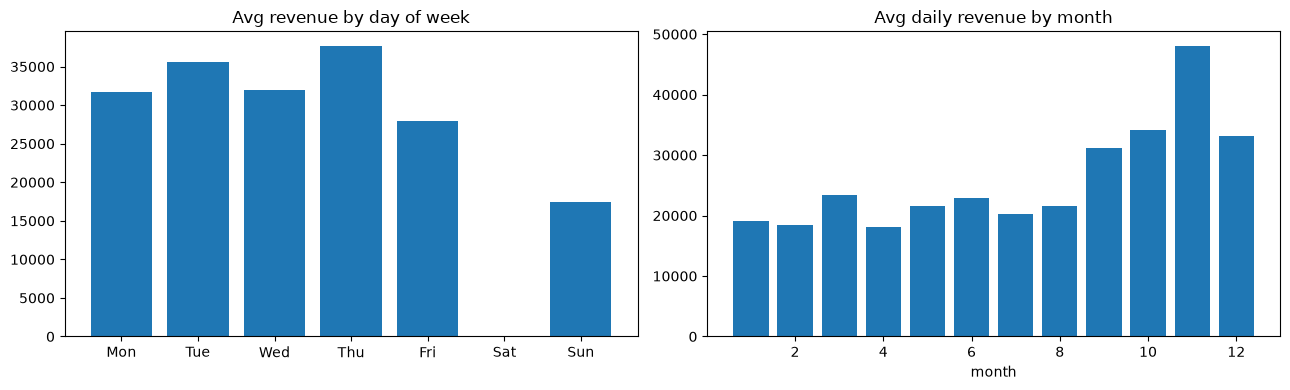

In [193]:
# Weekly and monthly cycles
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dow = daily_rev.groupby(daily_rev.index.dayofweek).mean().reindex(range(7))
ax[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values)
ax[0].set_title("Avg revenue by day of week")
moy = daily_rev.groupby(daily_rev.index.month).mean().reindex(range(1, 13))
ax[1].bar(range(1, 13), moy.values)
ax[1].set_title("Avg daily revenue by month")
ax[1].set_xlabel("month")
plt.tight_layout()
plt.show()

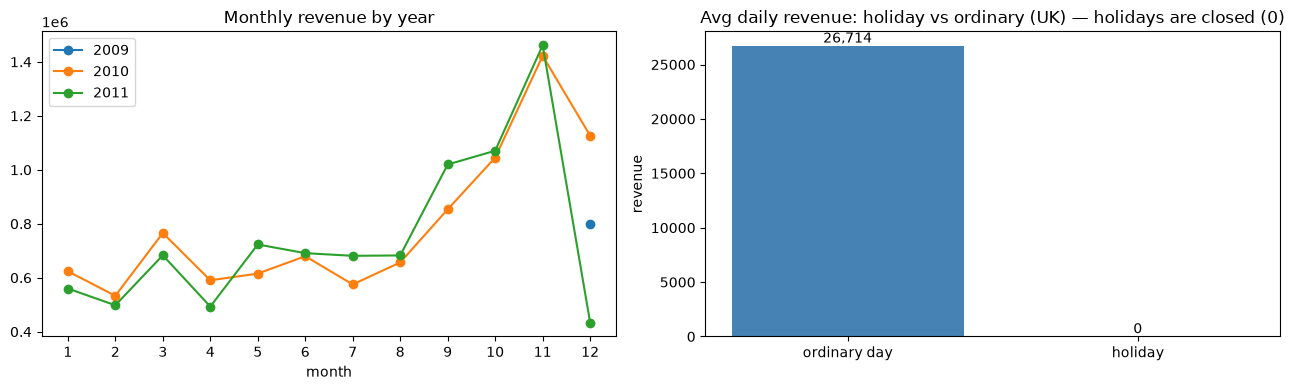

In [194]:
# Yearly cycle (does the shape repeat?) and holiday effect
import holidays as holidays_lib

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for yr in sorted(set(monthly_rev.index.year)):
    ym = monthly_rev[monthly_rev.index.year == yr]
    ax[0].plot(ym.index.month, ym.values, "-o", label=str(yr))
ax[0].set_title("Monthly revenue by year")
ax[0].set_xlabel("month")
ax[0].set_xticks(range(1, 13))
ax[0].legend()

yrs = range(int(daily_rev.index.year.min()), int(daily_rev.index.year.max()) + 1)
gb = holidays_lib.country_holidays("GB", years=list(yrs))
is_hol = daily_rev.index.normalize().isin(set(gb))
means = [daily_rev[~is_hol].mean(), daily_rev[is_hol].mean()]
bars = ax[1].bar(["ordinary day", "holiday"], means, color=["steelblue", "crimson"])
for b, m in zip(bars, means):
    ax[1].text(b.get_x() + b.get_width() / 2, m, f"{m:,.0f}", ha="center", va="bottom")
ax[1].set_title("Avg daily revenue: holiday vs ordinary (UK) — holidays are closed (0)")
ax[1].set_ylabel("revenue")
plt.tight_layout()
plt.show()

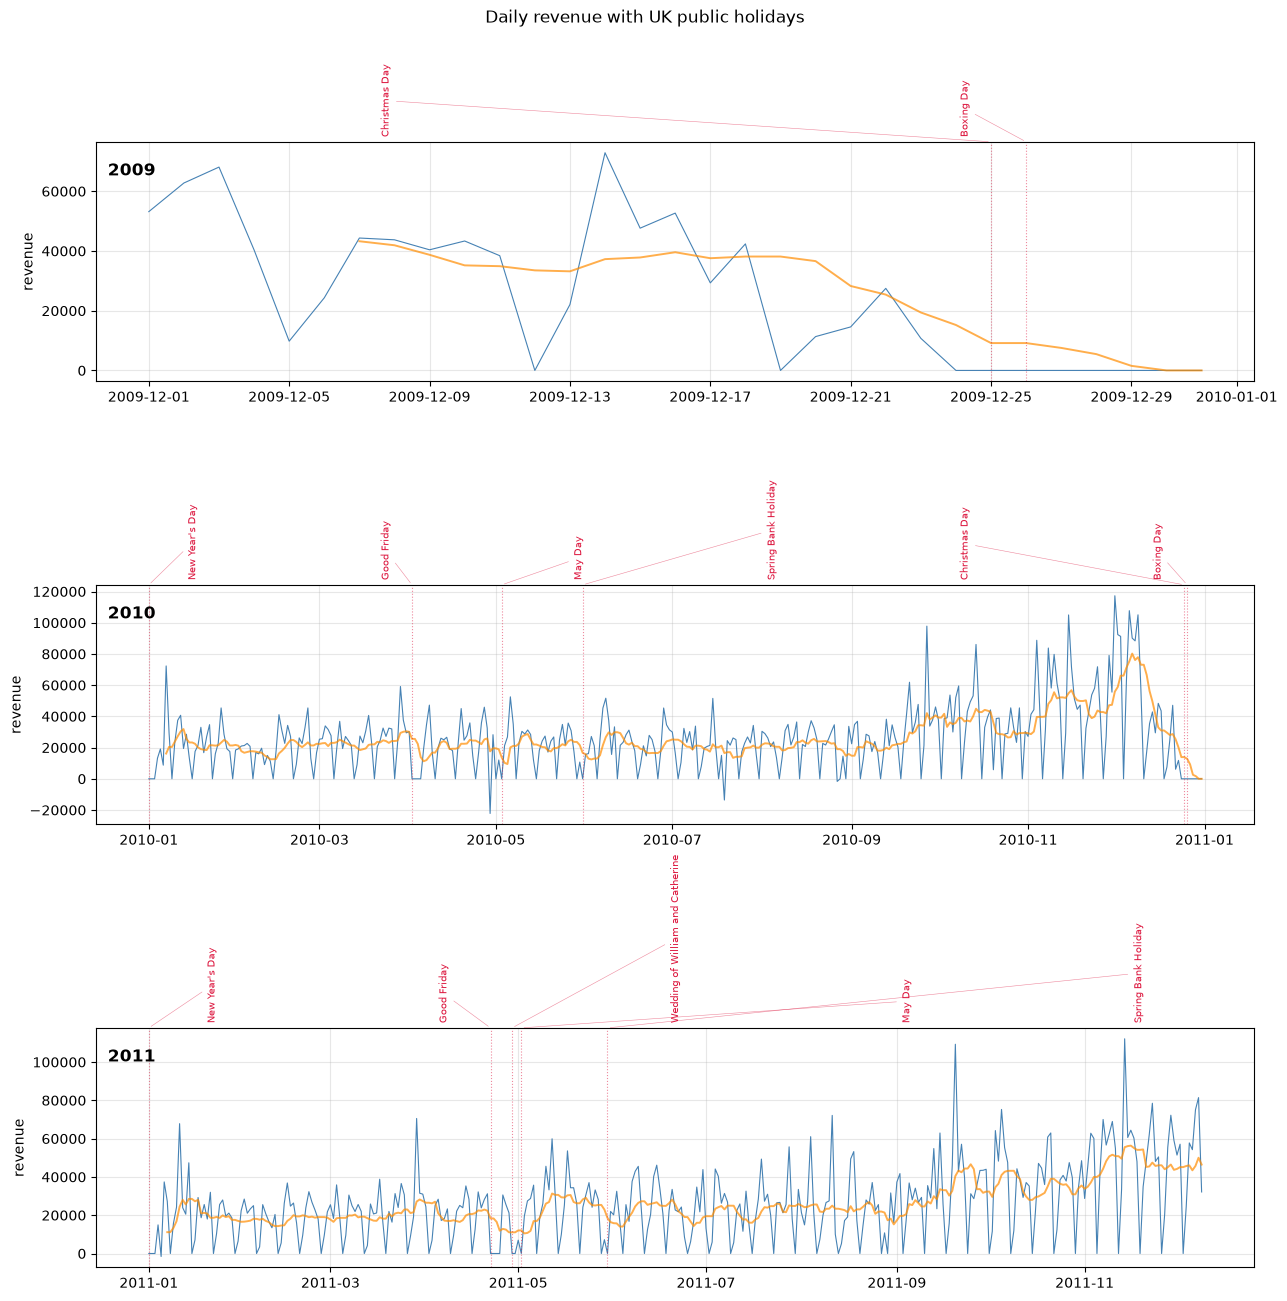

In [195]:
# Daily revenue per year, with UK public holidays marked and named.
import holidays as holidays_lib

years = sorted(set(daily_rev.index.year))
gb = holidays_lib.country_holidays("GB", years=years)

fig, axes = plt.subplots(len(years), 1, figsize=(13, 4.3 * len(years)))
axes = np.atleast_1d(axes)
for ax, yr in zip(axes, years):
    s = daily_rev[daily_rev.index.year == yr]
    ax.plot(s.index, s.values, lw=0.8, color="steelblue")  # actual daily revenue
    ax.plot(s.index, s.rolling(7).mean(), lw=1.4, color="darkorange", alpha=0.7)  # 7-day trend guide
    ax.text(0.01, 0.86, str(yr), transform=ax.transAxes, fontweight="bold", fontsize=12)
    ax.set_ylabel("revenue")
    ax.grid(alpha=0.3)
    hs = [
        (pd.Timestamp(d), n)
        for d, n in sorted(gb.items())
        if pd.Timestamp(d).year == yr
        and s.index.min() <= pd.Timestamp(d) <= s.index.max()
        and "(observed)" not in n.lower()
    ]
    for k, (d, name) in enumerate(hs):
        ax.axvline(d, color="crimson", ls=":", lw=0.8, alpha=0.5)
        ax.annotate(
            name,
            xy=(d, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=((k + 0.5) / len(hs), 1.02),
            textcoords="axes fraction",
            rotation=90,
            va="bottom",
            ha="center",
            fontsize=7,
            color="crimson",
            arrowprops=dict(arrowstyle="-", color="crimson", lw=0.4, alpha=0.5),
        )
fig.suptitle("Daily revenue with UK public holidays", y=1.005, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(hspace=0.85)
plt.show()

## 6. Orders, returns & concentration

The rows above are line items; a business works in orders (invoices). This looks at order size and value, the weight of returns, and how concentrated revenue is across customers and products.

Orders (invoices): 45,336
Average order value: 459.10
Median items per order: 13


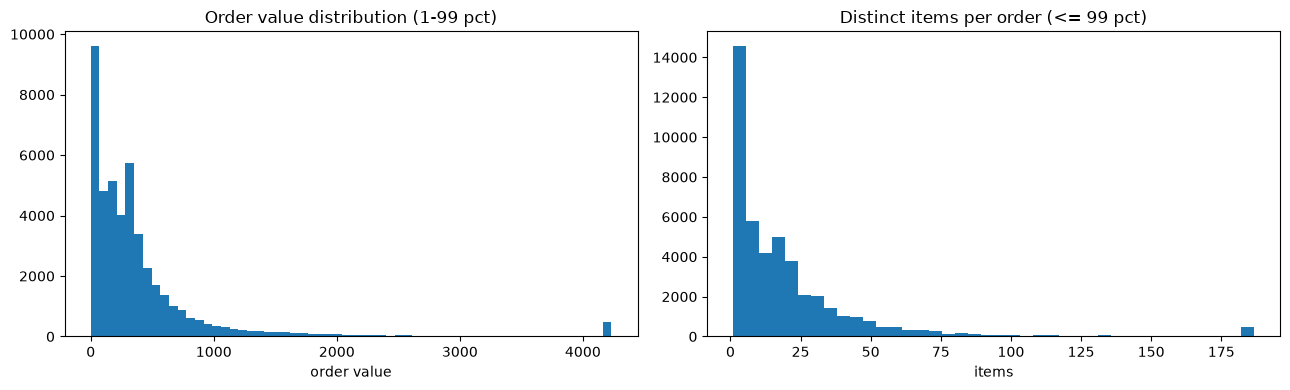

In [196]:
# Order-level view: an order is one invoice, excluding cancellations (invoice starts with C).
orders = (
    raw[~raw["Invoice"].astype(str).str.startswith("C")]
    .groupby("Invoice")
    .agg(items=("StockCode", "nunique"), units=("Quantity", "sum"), value=("revenue", "sum"))
)
print("Orders (invoices):", f"{len(orders):,}")
print("Average order value:", f"{orders['value'].mean():,.2f}")
print("Median items per order:", int(orders["items"].median()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ov = orders["value"]
ax[0].hist(ov.clip(ov.quantile(0.01), ov.quantile(0.99)), bins=60)
ax[0].set_title("Order value distribution (1-99 pct)")
ax[0].set_xlabel("order value")
ax[1].hist(orders["items"].clip(upper=orders["items"].quantile(0.99)), bins=40)
ax[1].set_title("Distinct items per order (<= 99 pct)")
ax[1].set_xlabel("items")
plt.tight_layout()
plt.show()

In [197]:
# Returns as a share of gross revenue
gross = raw.loc[raw["revenue"] > 0, "revenue"].sum()
returned = -raw.loc[raw["revenue"] < 0, "revenue"].sum()
print(
    f"Gross revenue: {gross:,.0f} | Returns & negatives: {returned:,.0f} "
    f"({returned / gross * 100:.1f}% of gross) | Net: {gross - returned:,.0f}"
)


# Revenue concentration: share held by the top slice of customers / products.
def top_share(col, fracs=(0.1, 0.2)):
    rev = raw.groupby(col)["revenue"].sum()
    rev = rev[rev > 0].sort_values(ascending=False)
    total = rev.sum()
    return {f"top {int(f * 100)}%": f"{rev.head(max(1, int(len(rev) * f))).sum() / total * 100:.0f}%" for f in fracs}


print("Customer revenue concentration:", top_share("Customer ID"))
print("Product revenue concentration :", top_share("StockCode"))

Gross revenue: 20,972,968 | Returns & negatives: 1,685,718 (8.0% of gross) | Net: 19,287,251
Customer revenue concentration: {'top 10%': '63%', 'top 20%': '77%'}
Product revenue concentration : {'top 10%': '63%', 'top 20%': '79%'}


## 7. Numeric distributions & outliers

Quantity and Price both have extreme values (bulk orders, returns, fee rows). The top plots are clipped to the 1st-99th percentile to show the shape of the bulk; the bottom plots show the full range on a log count axis, where the extreme values are visible.

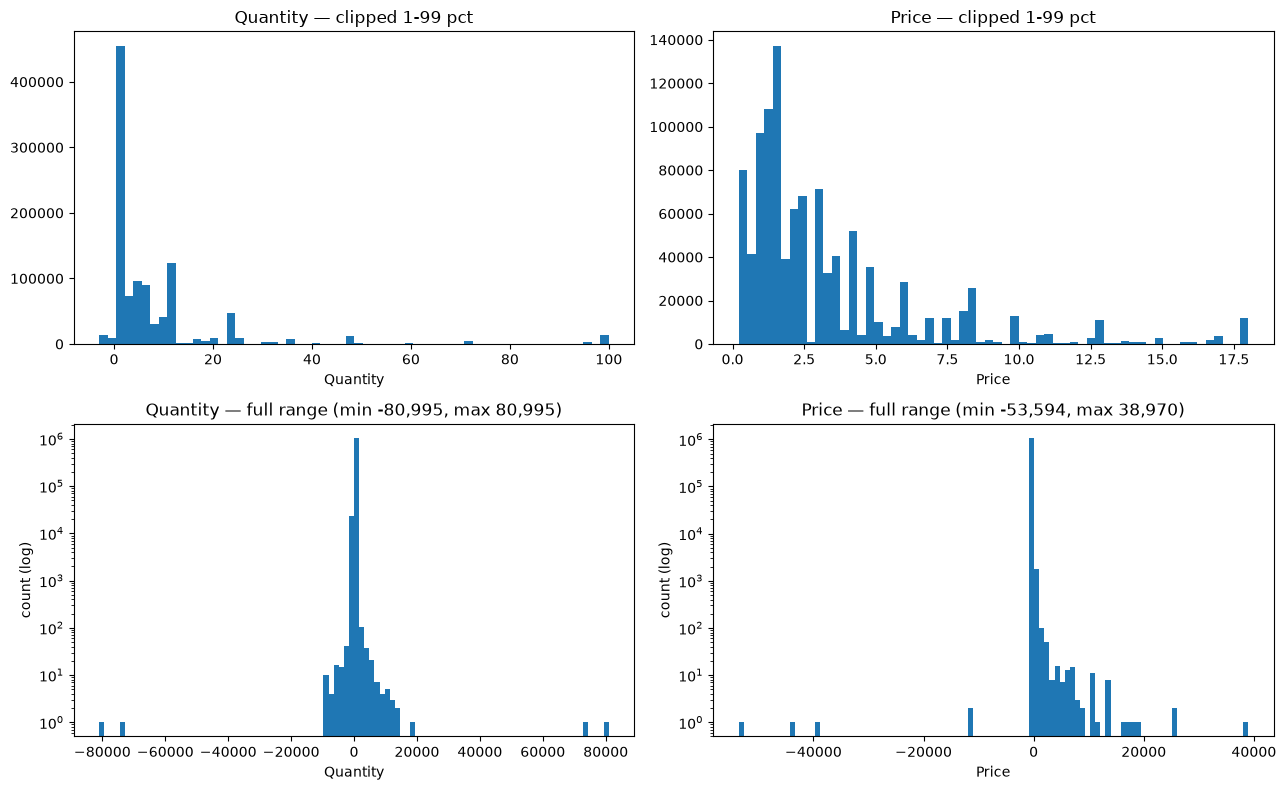

         Quantity       Price
count  1067371.00  1067371.00
mean         9.94        4.65
std        172.71      123.55
min     -80995.00   -53594.36
1%          -3.00        0.21
50%          3.00        2.10
99%        100.00       18.00
max      80995.00    38970.00


In [198]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for j, colname in enumerate(["Quantity", "Price"]):
    v = raw[colname]
    lo, hi = v.quantile(0.01), v.quantile(0.99)
    # Top row: clipped to 1-99 pct to show the shape of the bulk.
    ax[0, j].hist(v.clip(lo, hi), bins=60)
    ax[0, j].set_title(f"{colname} — clipped 1-99 pct")
    ax[0, j].set_xlabel(colname)
    # Bottom row: full unclipped range on a log count axis, showing the extremes.
    ax[1, j].hist(v, bins=100)
    ax[1, j].set_yscale("log")
    ax[1, j].set_title(f"{colname} — full range (min {v.min():,.0f}, max {v.max():,.0f})")
    ax[1, j].set_xlabel(colname)
    ax[1, j].set_ylabel("count (log)")
plt.tight_layout()
plt.show()
print(raw[["Quantity", "Price"]].describe(percentiles=[0.01, 0.5, 0.99]).round(2))

## 8. Field availability -> which KPIs the data supports

Each KPI needs certain fields. This maps what the dataset has to what can be computed — the basis for showing a KPI as available or unavailable.

In [199]:
cols = set(raw.columns)


def has(*need):
    return all(c in cols for c in need)


kpis = [
    ("Total revenue", has("Quantity", "Price", "InvoiceDate"), "Quantity, Price, InvoiceDate"),
    ("Revenue by product", has("Quantity", "Price", "StockCode"), "+ StockCode"),
    ("Revenue by region", has("Quantity", "Price", "Country"), "+ Country"),
    ("Average order value", has("Invoice", "Quantity", "Price"), "+ Invoice"),
    ("Units sold", has("Quantity"), "Quantity"),
    ("Unique customers / repeat", has("Customer ID"), "Customer ID (many missing)"),
    ("Return rate", has("Quantity", "Invoice"), "negative Quantity / C-invoices"),
    ("Gross margin / profit", has("Cost"), "needs a Cost/COGS column"),
]
kdf = pd.DataFrame(kpis, columns=["KPI", "computable", "required fields"])
kdf["computable"] = kdf["computable"].map({True: "yes", False: "no"})
kdf

,KPI,computable,required fields
0,Total revenue,yes,"Quantity, Price, InvoiceDate"
1,Revenue by product,yes,+ StockCode
2,Revenue by region,yes,+ Country
3,Average order value,yes,+ Invoice
4,Units sold,yes,Quantity
5,Unique customers / repeat,yes,Customer ID (many missing)
6,Return rate,yes,negative Quantity / C-invoices
7,Gross margin / profit,no,needs a Cost/COGS column


## 9. Takeaways

- The data is transaction-level and mostly clean, but has predictable issues the cleaning pipeline must handle: exact duplicate rows, ~a quarter of rows missing Customer ID, cancellations and negative-quantity returns, zero/negative prices, and non-product bookkeeping rows (postage, fees, adjustments) identified by non-5-digit stock codes.
- Quantity and Price are heavily skewed with extreme outliers, so any average or total should expect long tails.
- The UK dominates transactions and revenue; other countries are a long tail.
- Field coverage supports revenue, product, region, order-value, units, and return KPIs. Customer KPIs are limited by missing Customer IDs, and margin/profit is not computable without a cost column — a concrete input for KPI availability rules.
- Line items collapse to far fewer orders; order value and basket size are skewed, returns are a meaningful share of gross revenue, and revenue is concentrated in a small share of customers and products.
- Strong calendar structure a forecast must capture: weekly (Saturdays near zero), yearly (Nov-Dec peak), and public holidays that are non-trading days (zero revenue).